# HW1 Eigenfaces via PPCA Denoising (10pt)

**The idea:** a single photo corrupted with heavy Gaussian noise is unrecoverable — the noise variance dwarfs the signal. But if we have *many* different photos of the same face (different expressions, lighting, slight pose changes), the noise is independent across photos while the underlying face structure is shared. Probabilistic PCA (PPCA) pools all the noisy photos together, models that shared structure as a low-dimensional linear subspace (the "eigenfaces"), and reconstructs a clean estimate of each photo from it.

In this homework, you will reconstract corrupted with heavy Gaussian noise images.

1. Data preparation (3pt) (You can skip this part, if using provided data)
2. Data corruption (1pt)
3. PPCA implementation (3pt)
4. Denoising reconstruction, effect of *k* (number of components) (1pt)
5. Discussion (2pt)

In [ ]:
from PIL import Image
import glob
import os
import numpy as np
import matplotlib.pyplot as plt
rng_global = np.random.default_rng(42)
plt.rcParams['figure.facecolor'] = 'white'

## 1. Data Preparation
Use about 20 of *yours own* photos (it can be less, we use data augmentation). Create a folder (left-side pannel) and download the pictures (you can also mount googldrive). Use function **`load_your_own_photos(folder)`** which loads a folder of real images (PIL, with optional OpenCV face-cropping).

In [ ]:
#We use older version of CV library
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python
!pip install -q opencv-python==4.10.0.84

In [ ]:
import cv2

print(cv2.__version__)
print(hasattr(cv2, "CascadeClassifier"))

4.10.0
True


In [ ]:
H=W=64
def load_your_own_photos(
    folder,
    size=(H, W),
    pad_frac=0.25,
    detect_max_side=1000
):
    """
    Load and preprocess face photos.

    If OpenCV is available, automatically detect and crop the largest face.
    Otherwise, resize the original image.
    """

    paths = sorted(glob.glob(os.path.join(folder, "*")))

    if len(paths) == 0:
        raise ValueError(f"No image files found in {folder}")

    imgs = []

    # Try to initialize OpenCV face detector
    face_cascade = None

    try:
        cascade_path = (cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
        face_cascade = cv2.CascadeClassifier(cascade_path)

    except Exception:
        print("OpenCV not available; using original images without face detection.")

    for p in paths:

        im = Image.open(p).convert("L")
        arr = np.array(im)

        # Face detection
        if face_cascade is not None:

            # Downscale before detection
            scale = min(1.0, detect_max_side / max(arr.shape))

            if scale < 1.0:
                small = cv2.resize(
                    arr,
                    (
                        int(arr.shape[1] * scale),
                        int(arr.shape[0] * scale)
                    )
                )
            else:
                small = arr

            faces = face_cascade.detectMultiScale(
                small,
                scaleFactor=1.1,
                minNeighbors=5,
                minSize=(60, 60)
            )

            if len(faces) > 0:
                # Select largest detected face
                x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
                # Map coordinates back to original image
                x, y, w, h = [int(v / scale) for v in (x, y, w, h)]
                # Add padding
                pad = int(pad_frac * w)
                x0 = max(0, x - pad)
                y0 = max(0, y - pad)
                x1 = min(arr.shape[1], x + w + pad)
                y1 = min(arr.shape[0], y + h + pad)
                arr = arr[y0:y1, x0:x1]
            else:
                print(f"Warning: no face detected in {p}; using entire image.")

        # Resize
        im2 = Image.fromarray(arr).resize(size)
        imgs.append(np.asarray(im2, dtype=np.float64) / 255.0)

    return np.stack(imgs)


def augment_dataset(X, target_n, seed=0):
    """
    Expand a small real photo set using small random
    rotation, brightness, and horizontal flip augmentations.
    """
    r = np.random.default_rng(seed)
    N0, H_, W_ = X.shape
    out = []

    for i in range(target_n):
        img = X[i % N0]
        im = Image.fromarray((img * 255).astype(np.uint8))

        # Small rotation
        angle = r.uniform(-5, 5)

        im = im.rotate(
            angle,
            resample=Image.BILINEAR,
            fillcolor=int(img.mean() * 255)
        )

        arr = (np.asarray(im, dtype=np.float64) / 255.0)

        # Brightness
        arr = np.clip(arr * r.uniform(0.85, 1.15), 0, 1)

        # Horizontal flip
        if r.random() < 0.5:
            arr = arr[:, ::-1]

        out.append(arr)

    return np.stack(out)

In [ ]:
X_clean = load_your_own_photos("/content/images/")        # <-- swap in real photos#
N = X_clean.shape[0] #
if N < 30:                                                # got fewer real photos than that?#
  X_clean = augment_dataset(X_clean, target_n=250)        # boost effective N via augmentation#
N = X_clean.shape[0]#
print(N)

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for i, ax in enumerate(axes.flat):
  ax.imshow(X_clean[i % N], cmap='gray', vmin=0, vmax=1)
  ax.axis('off')
plt.suptitle("The clean dataset: same 'person', varying expression / lighting / position")
plt.tight_layout()
plt.show()

## 2. Corrupting the Data with Heavy Gaussian Noise
We add i.i.d. $\mathcal N(0,\sigma^2)$ noise, independently, to every pixel of every image. The noise level below (`noise_std = 0.3`) is chosen so that **a single image is genuinely unrecognizable** — check the signal-to-noise ratio printed below, and look at the images: this is not a mild perturbation.

In [ ]:
noise_std = 0.3 #0.22   # tune this -- try 0.1 (mild) up to 0.9 (extreme) and see what breaks
D = H * W
X_flat = X_clean.reshape(N, D)
noise_rng = np.random.default_rng(1)
X_noisy_flat = X_flat + noise_rng.normal(0, noise_std, size=X_flat.shape)
X_noisy = X_noisy_flat.reshape(N, H, W)
signal_var = X_flat.var()
print(f"per-pixel signal variance: {signal_var:.4f}")
print(f"per-pixel noise variance:  {noise_std**2:.4f}")
print(f"single-image SNR: {signal_var/noise_std**2:.3f}  (well below 1 = noise dominates a lone photo)")

In [ ]:
# Uncomment, if you want to use provided dataset and go directly to visualisation of X_noisy
# from pathlib import Path
# from PIL import Image
# !unzip images.zip
# def load_image_array(in_dir="images_out", normalize=True):
#     """Returns array of shape (N, 64, 64)."""
#     in_dir = Path(in_dir)
#     paths = sorted(in_dir.glob("*.png"))  # zero-padded names sort correctly

#     imgs = [np.array(Image.open(p).convert("L")) for p in paths]
#     arr = np.stack(imgs, axis=0)  # (N, H, W), uint8

#     if normalize:
#         arr = arr.astype(np.float32) / 255.0

#     return arr

# X_noisy = load_image_array("images_out", normalize=True)
# print(X_noisy.shape, X_noisy.dtype, X_noisy.min(), X_noisy.max())
# N=X_noisy.shape[0]
# H, W = X_noisy.shape[1], X_noisy.shape[2]
# X_noisy_flat = X_noisy.reshape(N, H*W)
# noise_std = 0.3

In [ ]:
fig, axes = plt.subplots(1, 8, figsize=(13, 1.9))
for i, ax in enumerate(axes.flat):
  ax.imshow(X_noisy[i], cmap='gray')
  ax.axis('off')
plt.suptitle(f"Heavily corrupted (σ={noise_std}) -- a single image alone tells you almost nothing")
plt.tight_layout()
plt.show()

## 3. PPCA Implementation: Theory Recap
PPCA assumes each observed (noisy) image $x_n \in \mathbb R^D$ was generated by:$$z_n \sim \mathcal N(0, I_k), \qquad x_n \mid z_n \sim \mathcal N(Wz_n + \mu,\ \sigma^2 I_D)$$i.e. a low-dimensional latent code $z_n$ (the "eigenface coordinates"), mapped into image space by $W \in \mathbb R^{D\times k}$, plus isotropic Gaussian noise. This is *exactly* the corruption process we just simulated, so PPCA is the statistically correct model for this problem, not just a convenient heuristic.

In [ ]:
def fit_ppca(X, k, n_iters=50, seed=0):
  """Fit PPCA by the closed-form MLE (Tipping & Bishop, 1999).
  X: (N, D) observed data.
  k: number of latent dimensions.
  n_iters: number of iterations to run.
  seed: random seed for initialization (optional).

  Returns mu (D,), W (D,k), sigma2 (scalar).
  """
  pass



In [ ]:
k = 7   # number of eigenfaces / latent dimensions

mu, W_ppca, sigma2 = fit_ppca(X_noisy_flat, k, n_iters=85)
print(f"estimated noise std: {np.sqrt(sigma2):.3f}   (true injected noise std: {noise_std})")

## 4. Denoising Reconstruction
Given a fitted PPCA model, the denoised estimate of each image is the **posterior mean** of $x$ given the noisy observation -- not a naive projection. This matters: PPCA's posterior mean applies a *shrinkage* factor based on how much of each direction's variance is signal vs. noise (a Wiener-filter-like correction), whereas plain PCA projection implicitly assumes the top-$k$ directions are noise-free. We implement and compare both, so you can see the difference is real, not just theoretical.

In [ ]:
def ppca_reconstruct(X, mu, W_, sigma2):
  """Posterior-mean (Bayesian, shrinkage-aware) denoising."""
  k = W_.shape[1]
  M = W_.T @ W_ + sigma2*np.eye(k)
  Z = (X - mu) @ W_ @ np.linalg.inv(M).T     # E[z | x] for every sample
  Xhat = Z @ W_.T + mu
  return Xhat, Z

def naive_pca_reconstruct(X, mu, Vt_k):
  """Plain PCA projection (no noise-aware shrinkage) -- for comparison."""
  Z = (X - mu) @ Vt_k.T
  return Z @ Vt_k + mu

Xhat_ppca_flat, Z = ppca_reconstruct(X_noisy_flat, mu, W_ppca, sigma2)
Xhat_ppca = Xhat_ppca_flat.reshape(N, H, W)
Vt_k = np.linalg.svd(X_noisy_flat - X_noisy_flat.mean(0), full_matrices=False)[2][:k]
Xhat_pca_flat = naive_pca_reconstruct(X_noisy_flat, X_noisy_flat.mean(0), Vt_k)
mse_noisy = np.mean((X_noisy_flat - X_flat)**2)
mse_pca   = np.mean((Xhat_pca_flat  - X_flat)**2)
mse_ppca  = np.mean((Xhat_ppca_flat - X_flat)**2)
print("MSE against the (secretly known, for evaluation only) clean ground truth:")
print(f"  raw noisy input, no denoising: {mse_noisy:.4f}")
print(f"  naive PCA reconstruction:      {mse_pca:.4f}")
print(f"  PPCA reconstruction:           {mse_ppca:.4f}   ({100*(1-mse_ppca/mse_noisy):.1f}% improvement over raw noisy)")

In [ ]:
fig, axes = plt.subplots(3, 8, figsize=(13, 5.3))
for i in range(8):
  axes[0,i].imshow(X_clean[i], cmap='gray', vmin=0, vmax=1);
  axes[0,i].axis('off')
  axes[1,i].imshow(X_noisy[i], cmap='gray');
  axes[1,i].axis('off')
  axes[2,i].imshow(np.clip(Xhat_ppca[i],0,1), cmap='gray', vmin=0, vmax=1);
  axes[2,i].axis('off')
for r, label in enumerate(["Original (clean)", "Corrupted (noisy)", "PPCA reconstruction"]):
  axes[r,0].text(-0.15, 0.5, label, transform=axes[r,0].transAxes,
                 rotation=90, va='center', ha='right', fontsize=10)
plt.tight_layout()
plt.show()

## 4(a). Effect of $k$:
too few components loses real signal (underfitting); too many starts fitting noise (overfitting) -- a direct bias/variance tradeoff.

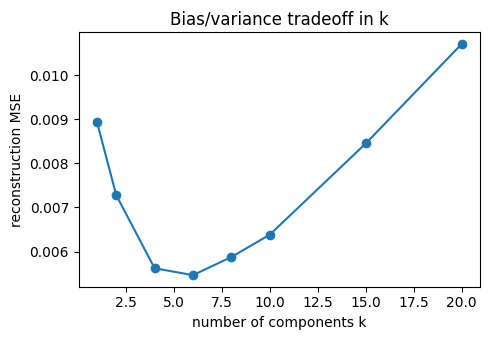

In [ ]:
ks = [1, 2, 4, 6, 8, 10, 15, 20]
mses_k = []
for kt in ks:
  mu_t, W_t, s2_t = fit_ppca(X_noisy_flat, kt)
  Xhat_t, _ = ppca_reconstruct(X_noisy_flat, mu_t, W_t, s2_t)
  mses_k.append(np.mean((Xhat_t - X_flat)**2))
plt.figure(figsize=(5,3.5))
plt.plot(ks, mses_k, 'o-')
plt.xlabel("number of components k");
plt.ylabel("reconstruction MSE")
plt.title("Bias/variance tradeoff in k")
plt.tight_layout();
plt.show()

## 5. Discussion
1. Why does a *single* noisy photo carry essentially no usable information, while 30-50 of them (at the *same* per-photo noise level) can be pooled into a clear reconstruction? Which specific quantity in the PPCA formulas is doing that work?

2. In the $k$-sweep plot, explain the shape of the curve in terms of bias and variance. What determines the location of the minimum?

3. Is there a connection between $N$, $k$, and $\sigma$?

4. (Open-ended) If you doubled the noise level, roughly how many additional photos would you need to reach the same reconstruction quality?